# 1-01 어닝 서프라이즈 — 실적이 증권사 예상과 얼마나 달랐나 (최근 8분기·여러 종목)

**질문 예시:** "삼성전자 작년 실적 컨센 대비 어땠어?", "SK하이닉스·현대차·NAVER 최근 분기들 서프라이즈 비교해줘"

CHECK 원본(`1_기업펀더멘털/01_어닝서프라이즈`)은 IFRS 실적과 날짜별 컨센서스 스냅샷을 비교했습니다.
DeepSearch로도 같은 계산이 됩니다. 이 노트북은 **여러 종목 × 최근 8분기**의 서프라이즈 이력을 한 표로 만듭니다.
발표일 전후 주가 반응은 [1-03 실적발표 이벤트 스터디](03_earnings_event_study.ipynb)에서 봅니다.

| 항목 | DeepSearch |
|---|---|
| 분기 실적(매출·영업이익·지배순이익·EPS) | `GetFinancialStatements` 분기·3개월 증분 — **여러 종목 한 번에** |
| 발표일 | 거래소 공시 `연결재무제표기준영업(잠정)실적(공정공시)` (`DocumentSearch`, 공시) |
| 발표 직전 컨센서스 | `SearchFirmFundamentalsForecasts` 증권사·작성일별 추정치 → 발표 전 90일 안의 증권사별 최신값 평균 |

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/1_fundamentals/01_earnings_surprise.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
STOCKS = {"KRX:005930": "삼성전자", "KRX:000660": "SK하이닉스", "KRX:005380": "현대차", "KRX:035420": "NAVER"}
N_Q = 8            # 최근 몇 분기
LOOKBACK = 90      # 발표 전 며칠 안의 추정치를 컨센서스로 볼지

## 1. 분기 실적 (여러 종목 한 번에)
연결·IFRS, 3개월 증분(누적 아님) 기준입니다. 지배순이익은 `당기순이익지배기업지분`, EPS는 `기본주당순손익`입니다.

In [4]:
ACC = {"수익": "매출", "영업이익(손실)": "영업이익", "당기순이익지배기업지분": "지배순이익", "기본주당순손익": "EPS"}
start = (pd.Timestamp(ASOF) - pd.DateOffset(months=3 * N_Q + 6)).date()
fs = ds_df(f'GetFinancialStatements([{", ".join(STOCKS)}], report_type="IFRS", consolidated=True, is_annual=False, '
           f'is_accumulated=False, report_ids="Income", date_from={start}, date_to={ASOF})')
act = (fs[fs["name_ko"].isin(ACC)].pivot_table(index=["symbol", "date"], columns="name_ko", values="value", aggfunc="first")
       .rename(columns=ACC).reset_index())
quarters = sorted(act["date"].unique())[-N_Q:]
act = act[act["date"].isin(quarters)]
print("분기:", ", ".join(pd.Timestamp(q).strftime("%Y-%m") for q in quarters))
t = act.copy()
t["종목"] = t["symbol"].map(STOCKS); t["분기"] = t["date"].dt.strftime("%Y-%m")
for c in ("매출", "영업이익", "지배순이익"):
    t[c] = t[c].map(krw)
t.pivot_table(index="분기", columns="종목", values="영업이익", aggfunc="first")

분기: 2024-12, 2025-03, 2025-06, 2025-09, 2025-12, 2026-03, 2026-06, 2026-09


종목,NAVER,SK하이닉스,삼성전자,현대차
분기,,,,
2024-12,"5,420억",8.1조,6.5조,2.8조
2025-03,"5,053억",7.4조,6.7조,3.6조
2025-06,"5,216억",9.2조,4.7조,3.6조
2025-09,"5,706억",11.4조,12.2조,2.5조
2025-12,"6,106억",19.2조,20.1조,1.7조
2026-03,"5,418억",37.6조,57.2조,2.5조
2026-06,"5,203억",60.5조,89.5조,2.9조
2026-09,NaN,83.3조,107.4조,2.7조


### (참고) 자연어 분기 질의와 비교
`KRX:005930 시작-끝 분기 당기순이익 분기 기본주당순이익` 같은 자연어 질의도 분기 값을 줍니다.
하지만 **범위 첫 행이 4분기면 분기가 아니라 연간 값이 나옵니다**(아래 2024-12-31). 분기 실적은 `GetFinancialStatements`를 쓰세요.

In [5]:
q0, q1 = pd.Timestamp(quarters[0]) - pd.offsets.QuarterBegin(startingMonth=1), pd.Timestamp(quarters[-1])
nl = ds_df(f"KRX:005930 {q0.date()}-{q1.date()} 분기 당기순이익 분기 기본주당순이익")
nl.columns = ["date", "symbol", "entity_name", "자연어: 당기순이익", "자연어: EPS"]
fs_cmp = fs[(fs["symbol"] == "KRX:005930") & fs["name_ko"].isin(["총당기순이익", "기본주당순손익"])] \
    .pivot_table(index="date", columns="name_ko", values="value").rename(columns={"총당기순이익": "함수: 당기순이익", "기본주당순손익": "함수: EPS"})
cmp_ = nl.set_index("date")[["자연어: 당기순이익", "자연어: EPS"]].join(fs_cmp)
cmp_["일치"] = (cmp_["자연어: 당기순이익"] - cmp_["함수: 당기순이익"]).abs() < 1e9
cmp_.assign(**{c: cmp_[c].map(krw) for c in ("자연어: 당기순이익", "함수: 당기순이익")})

,자연어: 당기순이익,자연어: EPS,함수: EPS,함수: 당기순이익,일치
date,,,,,
2024-12-31,34.5조,4950,1116.0,7.8조,False
2025-03-31,8.2조,1192,1192.0,8.2조,True
2025-06-30,5.1조,737,737.0,5.1조,True
2025-09-30,12.2조,1795,1795.0,12.2조,True
2025-12-31,19.6조,2881,2881.0,19.6조,True
2026-03-31,47.2조,7123,7123.0,47.2조,True
2026-06-30,71.6조,10827,10827.0,71.6조,True
2026-09-30,75.1조,11431,11431.0,75.1조,True


## 2. 발표일 찾기
거래소 공시 가운데 **`연결재무제표기준영업(잠정)실적`**만 씁니다. 현대차는 월별 판매 실적도 `영업(잠정)실적`이라는 제목으로 내기 때문입니다.
`[기재정정]`은 빼고, 분기 말 다음 날부터 100일 안의 **첫 공시**를 그 분기의 발표로 봅니다(삼성전자는 분기 첫 주 잠정 발표가 여기에 해당).
공시 검색은 한 번에 1년까지라 두 번에 나눠 찾습니다.

In [6]:
codes = " or ".join(s.split(":")[1] for s in STOCKS)
ann = []
a = pd.Timestamp(quarters[0])
while a < pd.Timestamp(ASOF):
    b = min(a + pd.DateOffset(days=364), pd.Timestamp(ASOF))
    _, d = doc_search("company", ["disclosure"], f"securities.symbol:({codes}) and title:잠정", a.date(), b.date(), count=100)
    ann.append(d)
    a = b + pd.Timedelta(days=1)
ann = pd.concat(ann, ignore_index=True)
ann = ann[ann["title"].str.contains("연결재무제표기준영업\\(잠정\\)실적") & ~ann["title"].str.contains("정정")]
ann["symbol"] = "KRX:" + ann["symbols"].str.split(",").str[0].str.strip()

def announce(sym, q_end):
    d = ann[(ann["symbol"] == sym) & (ann["created_at"] > q_end) & (ann["created_at"] <= q_end + pd.Timedelta(days=100))]
    return d["created_at"].min() if len(d) else pd.NaT

act["발표"] = [announce(s, q) for s, q in zip(act["symbol"], act["date"])]
act.assign(종목=act["symbol"].map(STOCKS), 분기=act["date"].dt.strftime("%Y-%m")) \
   .pivot_table(index="분기", columns="종목", values="발표", aggfunc="first")

종목,NAVER,SK하이닉스,삼성전자,현대차
분기,,,,
2024-12,2025-02-07 07:45:59,2025-01-23 07:53:47,2025-01-08 08:37:22,2025-01-23 13:59:19
2025-03,2025-05-09 08:06:10,2025-04-24 07:45:58,2025-04-08 08:02:52,2025-04-24 14:01:38
2025-06,2025-08-08 08:09:27,2025-07-24 07:35:51,2025-07-08 07:42:30,2025-07-24 14:06:25
2025-09,2025-11-05 08:08:33,2025-10-29 07:36:22,2025-10-14 07:44:33,2025-10-30 14:04:16
2025-12,2026-02-06 07:43:25,2026-01-28 16:37:38,2026-01-08 07:42:37,2026-01-29 13:59:54
2026-03,2026-04-30 08:07:14,2026-04-23 07:36:18,2026-04-07 07:43:30,2026-04-23 14:11:58
2026-06,2026-08-07 08:14:01,2026-07-29 07:45:10,2026-07-07 07:41:05,2026-07-23 13:59:41
2026-09,NaT,2026-10-28 08:30:30,2026-10-08 07:57:39,2026-10-29 13:23:34


## 3. 발표 직전 컨센서스와 서프라이즈
분기 추정치는 결산월 코드 F(3월)·X(6월)·Y(9월)·Z(12월)로 들어 있고, `forecast_date`가 대상 분기(YYYYMM)입니다.
- 발표 시각 **이전** `LOOKBACK`일 안에 낸 추정치만 쓰고, 증권사마다 가장 최근 것 하나만 남깁니다.
- 입력 오류(다른 항목 값을 넣은 경우 등)를 걸러내려고 **중앙값의 1/3~3배를 벗어난 추정치는 뺍니다.**
- 순이익 추정치(`csd_net_income`)는 지배순이익과 비교합니다. **분기 EPS 추정치(`csd_eps`)는 비어 있어** EPS 서프라이즈는 계산하지 않습니다.

In [7]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # 분기 EPS 열이 통째로 비어 생기는 pandas 경고
fcs = []
for sym in STOCKS:                                   # 종목당 1회 (목록으로 넣으면 첫 종목만 옴)
    f = ds_df(f"SearchFirmFundamentalsForecasts({sym}, last_only=False, date_from={start}, date_to={ASOF})")
    if not f.empty:
        fcs.append(f.assign(symbol=sym))
fc = pd.concat(fcs, ignore_index=True)
fc = fc[fc["accounting_type"].isin(["F", "X", "Y", "Z"])]
print("분기 추정치 중 EPS가 채워진 행:", int(fc["csd_eps"].notna().sum()), "/", len(fc))

FIELDS = {"매출": "csd_revenue", "영업이익": "csd_operating_income", "지배순이익": "csd_net_income"}

def consensus(sym, q_end, cut):
    f = fc[(fc["symbol"] == sym) & (fc["forecast_date"] == q_end.strftime("%Y%m")) &
           (fc["date"] < cut.normalize()) & (fc["date"] >= cut.normalize() - pd.Timedelta(days=LOOKBACK))]
    out = {}
    for name, col in FIELDS.items():
        g = f.dropna(subset=[col]).sort_values("date").groupby("inst_code").tail(1)[col]
        if len(g):
            med = g.median()
            g = g[(g > med / 3) & (g < med * 3)] if med > 0 else g
        out[name] = g.mean() if len(g) else None
        out[name + " 증권사 수"] = len(g)
    return out

rows = []
for _, r in act.iterrows():
    cut = r["발표"] if pd.notna(r["발표"]) else r["date"] + pd.Timedelta(days=45)
    c = consensus(r["symbol"], r["date"], cut)
    row = {"종목": STOCKS[r["symbol"]], "분기": r["date"].strftime("%Y-%m"),
           "발표": r["발표"].date() if pd.notna(r["발표"]) else "(공시 없음: 분기말+45일 기준)"}
    for name in FIELDS:
        cons, real = c[name], r[name]
        row[name + " 실제"] = real
        row[name + " 컨센서스"] = cons
        row[name + " 서프라이즈(%)"] = (real / cons - 1) * 100 if cons and real is not None and cons > 0 else None
        row[name + " n"] = c[name + " 증권사 수"]
    rows.append(row)
sur = pd.DataFrame(rows)

show = sur[["종목", "분기", "발표"]].copy()
for name in FIELDS:
    show[name] = [f"{krw(a)} vs {krw(b)} ({s:+.1f}%, {n}곳)" if pd.notna(s) else f"{krw(a)} (컨센서스 없음)"
                  for a, b, s, n in zip(sur[name + " 실제"], sur[name + " 컨센서스"], sur[name + " 서프라이즈(%)"], sur[name + " n"])]
show[show["종목"] == "삼성전자"].reset_index(drop=True)

분기 추정치 중 EPS가 채워진 행: 0 / 1163


,종목,분기,발표,매출,영업이익,지배순이익
0,삼성전자,2024-12,2025-01-08,"75.8조 vs 79.6조 (-4.8%, 7곳)","6.5조 vs 9.4조 (-30.8%, 7곳)","7.6조 vs 9.3조 (-18.5%, 2곳)"
1,삼성전자,2025-03,2025-04-08,"79.1조 vs 77.0조 (+2.7%, 6곳)","6.7조 vs 5.4조 (+23.7%, 6곳)","8.0조 vs 5.0조 (+60.6%, 1곳)"
2,삼성전자,2025-06,2025-07-08,"74.6조 vs 76.4조 (-2.4%, 3곳)","4.7조 vs 7.1조 (-34.5%, 3곳)",4.9조 (컨센서스 없음)
3,삼성전자,2025-09,2025-10-14,"86.1조 vs 83.4조 (+3.2%, 2곳)","12.2조 vs 10.4조 (+17.1%, 2곳)",12.0조 (컨센서스 없음)
4,삼성전자,2025-12,2026-01-08,"93.8조 vs 93.3조 (+0.6%, 3곳)","20.1조 vs 19.5조 (+3.1%, 3곳)","19.3조 vs 19.5조 (-1.1%, 1곳)"
5,삼성전자,2026-03,2026-04-07,"133.9조 vs 113.4조 (+18.1%, 6곳)","57.2조 vs 35.4조 (+61.8%, 6곳)","47.1조 vs 29.1조 (+62.1%, 2곳)"
6,삼성전자,2026-06,2026-07-07,"171.5조 vs 165.9조 (+3.4%, 7곳)","89.5조 vs 78.9조 (+13.4%, 6곳)","71.3조 vs 61.6조 (+15.8%, 1곳)"
7,삼성전자,2026-09,2026-10-08,"195.3조 vs 198.4조 (-1.6%, 5곳)","107.4조 vs 103.4조 (+3.9%, 5곳)","75.2조 vs 82.0조 (-8.3%, 2곳)"


## 4. 종목 비교 — 영업이익 서프라이즈 이력

In [8]:
op = sur.pivot_table(index="분기", columns="종목", values="영업이익 서프라이즈(%)")[list(STOCKS.values())]
op.round(1)

종목,삼성전자,SK하이닉스,현대차,NAVER
분기,,,,
2024-12,-30.8,1.3,-20.9,-0.0
2025-03,23.7,16.5,3.3,2.1
2025-06,-34.5,0.7,-3.7,-4.1
2025-09,17.1,0.4,3.3,1.2
2025-12,3.1,5.6,-35.2,0.5
2026-03,61.8,13.2,-7.9,-3.5
2026-06,13.4,-0.8,-8.3,-6.8
2026-09,3.9,7.7,10.0,NaN


In [9]:
stat = pd.DataFrame({
    "평균 서프라이즈(%)": op.mean(),
    "상회 분기 수": (op > 0).sum(),
    "계산된 분기 수": op.notna().sum(),
    "평균 증권사 수": sur.groupby("종목")["영업이익 n"].mean().reindex(op.columns),
}).round(1)
stat["상회 비율"] = (stat["상회 분기 수"] / stat["계산된 분기 수"]).map("{:.0%}".format)
stat

,평균 서프라이즈(%),상회 분기 수,계산된 분기 수,평균 증권사 수,상회 비율
종목,,,,,
삼성전자,7.2,6,8,4.8,75%
SK하이닉스,5.6,7,8,3.8,88%
현대차,-7.4,3,8,4.4,38%
NAVER,-1.5,3,7,3.9,43%


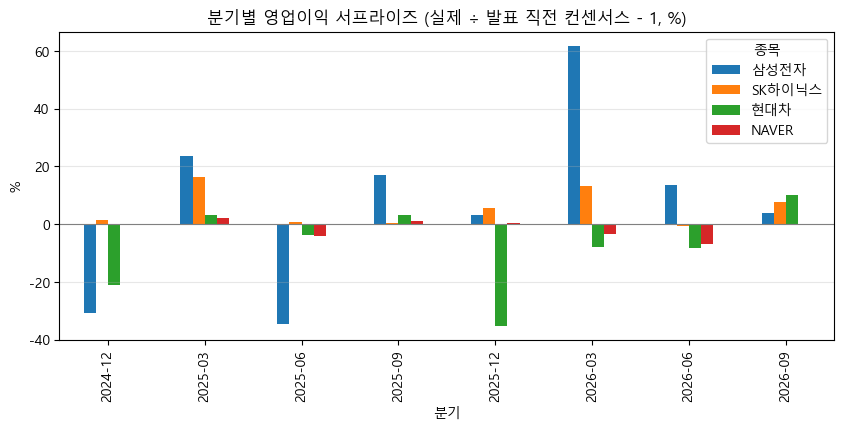

In [10]:
ax = op.plot(kind="bar", figsize=(10, 4), title="분기별 영업이익 서프라이즈 (실제 ÷ 발표 직전 컨센서스 - 1, %)")
ax.axhline(0, color="gray", lw=.8); ax.set_ylabel("%"); ax.grid(axis="y", alpha=.3)

### 다른 종목 표 (매출·영업이익·순이익)

In [11]:
for nm in list(STOCKS.values())[1:]:
    print(nm)
    display(show[show["종목"] == nm].drop(columns="종목").reset_index(drop=True))

SK하이닉스


,분기,발표,매출,영업이익,지배순이익
0,2024-12,2025-01-23,"19.8조 vs 19.7조 (+0.5%, 3곳)","8.1조 vs 8.0조 (+1.3%, 3곳)","8.0조 vs 6.6조 (+21.7%, 1곳)"
1,2025-03,2025-04-24,"17.6조 vs 17.2조 (+2.3%, 5곳)","7.4조 vs 6.4조 (+16.5%, 5곳)","8.1조 vs 4.8조 (+68.4%, 1곳)"
2,2025-06,2025-07-24,"22.2조 vs 20.5조 (+8.4%, 3곳)","9.2조 vs 9.2조 (+0.7%, 3곳)",7.0조 (컨센서스 없음)
3,2025-09,2025-10-29,"24.4조 vs 24.6조 (-0.7%, 4곳)","11.4조 vs 11.3조 (+0.4%, 4곳)","12.6조 vs 9.8조 (+28.4%, 2곳)"
4,2025-12,2026-01-28,"32.8조 vs 32.4조 (+1.4%, 3곳)","19.2조 vs 18.2조 (+5.6%, 3곳)","15.2조 vs 15.1조 (+1.1%, 2곳)"
5,2026-03,2026-04-23,"52.6조 vs 48.3조 (+8.9%, 6곳)","37.6조 vs 33.2조 (+13.2%, 6곳)","40.3조 vs 26.8조 (+50.7%, 5곳)"
6,2026-06,2026-07-29,"79.3조 vs 81.1조 (-2.1%, 2곳)","60.5조 vs 61.0조 (-0.8%, 2곳)","93.8조 vs 46.5조 (+101.6%, 1곳)"
7,2026-09,2026-10-28,"104.6조 vs 97.3조 (+7.5%, 4곳)","83.3조 vs 77.4조 (+7.7%, 4곳)","39.5조 vs 60.0조 (-34.1%, 4곳)"


현대차


,분기,발표,매출,영업이익,지배순이익
0,2024-12,2025-01-23,"46.6조 vs 45.4조 (+2.8%, 6곳)","2.8조 vs 3.6조 (-20.9%, 6곳)","2.3조 vs 2.9조 (-21.4%, 5곳)"
1,2025-03,2025-04-24,"44.4조 vs 42.9조 (+3.4%, 7곳)","3.6조 vs 3.5조 (+3.3%, 7곳)","3.2조 vs 3.2조 (-1.3%, 6곳)"
2,2025-06,2025-07-24,"48.3조 vs 45.9조 (+5.2%, 4곳)","3.6조 vs 3.7조 (-3.7%, 4곳)","3.0조 vs 3.4조 (-12.8%, 3곳)"
3,2025-09,2025-10-30,"46.7조 vs 44.9조 (+4.0%, 3곳)","2.5조 vs 2.5조 (+3.3%, 3곳)","2.3조 vs 2.2조 (+1.3%, 2곳)"
4,2025-12,2026-01-29,"46.8조 vs 48.6조 (-3.6%, 4곳)","1.7조 vs 2.6조 (-35.2%, 4곳)","1.0조 vs 2.2조 (-53.6%, 3곳)"
5,2026-03,2026-04-23,"45.9조 vs 45.6조 (+0.8%, 4곳)","2.5조 vs 2.7조 (-7.9%, 4곳)","2.3조 vs 2.4조 (-1.6%, 3곳)"
6,2026-06,2026-07-23,"49.2조 vs 48.9조 (+0.5%, 5곳)","2.9조 vs 3.1조 (-8.3%, 5곳)","2.5조 vs 2.8조 (-9.3%, 4곳)"
7,2026-09,2026-10-29,"45.1조 vs 43.5조 (+3.8%, 2곳)","2.7조 vs 2.4조 (+10.0%, 2곳)","1.7조 vs 2.1조 (-20.7%, 2곳)"


NAVER


,분기,발표,매출,영업이익,지배순이익
0,2024-12,2025-02-07,"2.9조 vs 2.8조 (+3.0%, 5곳)","5,420억 vs 5,421억 (-0.0%, 5곳)","5,539억 vs 4,026억 (+37.6%, 2곳)"
1,2025-03,2025-05-09,"2.8조 vs 2.8조 (-0.1%, 3곳)","5,053억 vs 4,948억 (+2.1%, 3곳)","4,248억 vs 3,493억 (+21.6%, 3곳)"
2,2025-06,2025-08-08,"2.9조 vs 2.9조 (+0.3%, 5곳)","5,216억 vs 5,438억 (-4.1%, 5곳)","4,888억 vs 4,546억 (+7.5%, 4곳)"
3,2025-09,2025-11-05,"3.1조 vs 3.0조 (+2.9%, 3곳)","5,706억 vs 5,637억 (+1.2%, 3곳)","7,264억 vs 4,954억 (+46.6%, 3곳)"
4,2025-12,2026-02-06,"3.2조 vs 3.2조 (-1.0%, 4곳)","6,106억 vs 6,078억 (+0.5%, 4곳)","3,132억 vs 5,914억 (-47.0%, 3곳)"
5,2026-03,2026-04-30,"3.2조 vs 3.2조 (+2.6%, 4곳)","5,418억 vs 5,615억 (-3.5%, 4곳)","2,853억 vs 5,245억 (-45.6%, 4곳)"
6,2026-06,2026-08-07,"3.4조 vs 3.4조 (+0.1%, 3곳)","5,203억 vs 5,583억 (-6.8%, 3곳)","6,986억 vs 4,783억 (+46.1%, 3곳)"


## 결과 읽는 법과 한계
- **서프라이즈 = 실제 ÷ 발표 직전 컨센서스 − 1.** +면 예상보다 잘 나왔다는 뜻입니다. 같은 종목이 계속 상회하면 증권사가 보수적으로 추정하는 경향이 있는 것입니다.
- 실제 값은 **확정 분기 재무제표** 기준입니다. 잠정 발표 수치와 조금 다를 수 있습니다.
- 컨센서스는 DeepSearch가 받는 증권사(분기 추정은 대개 3~9곳) 기준이라 시장 전체 컨센서스보다 얇습니다. 증권사 수(`n`)를 같이 보세요.
- **분기 EPS 컨센서스가 없어** EPS 서프라이즈는 계산하지 않습니다. 순이익 추정치는 일부 증권사만 냅니다.
- 발표 공시를 못 찾은 분기는 분기 말 + 45일을 기준 시점으로 씁니다(표에 표시). 재무제표가 아직 안 들어온 최신 분기는 표에서 빠집니다.
- **지배순이익은 분기 값이 튀는 경우가 있습니다**(예: SK하이닉스 2026-06 93.8조 → 2026-09 39.5조, 영업이익보다 큰 분기). 순이익 서프라이즈는 증권사 1~2곳 표본인 경우가 많으니 영업이익을 주로 보세요.